# Proyecto 2 · Movimiento, densidad temporal y conclusiones
## Dinámica entre frames y contexto de los pases

**CC3084 – Ciencia de Datos · Semestre II 2026**

Un pase es un patrón **espacio-temporal**: la señal clave es el **movimiento** entre
frames. Aquí se estudia la variable `motion` (diferencia absoluta media en escala de
grises entre dos frames muestreados consecutivos del mismo clip, separados ≈3 s) y se
cruza con la densidad temporal de los pases anotados en `train.csv` (contexto).

In [1]:
import pandas as pd, numpy as np, ast
import matplotlib.pyplot as plt
df = pd.read_csv('../data/frame_features.csv')
train = pd.read_csv('../data/train.csv')
# motion == 0 es el primer frame de cada clip (sin frame previo): faltante estructural
mv = df[df.motion > 0]
print('Frames con motion válido:', len(mv), 'de', len(df))
print('Movimiento medio:', round(mv.motion.mean(),2), '| desv:', round(mv.motion.std(),2))

Frames con motion válido: 1800 de 2000
Movimiento medio: 24.12 | desv: 7.04


## 1. Distribución del movimiento entre frames

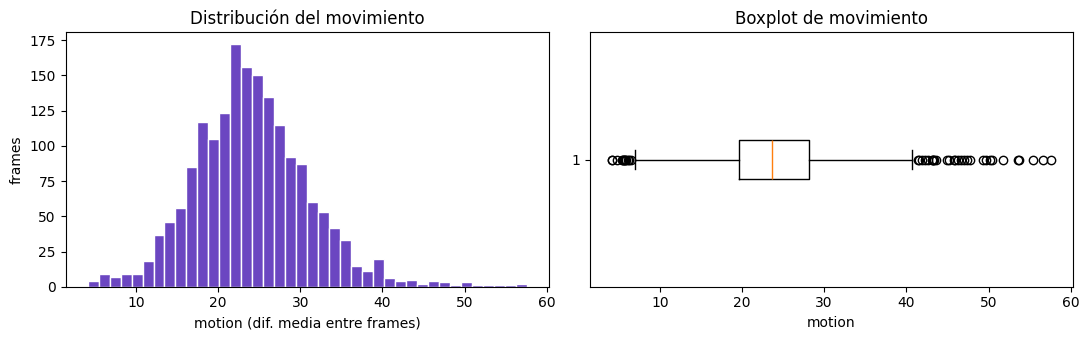

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(mv.motion, bins=40, color='#6b46c1', edgecolor='white')
ax[0].set(xlabel='motion (dif. media entre frames)', ylabel='frames', title='Distribución del movimiento')
ax[1].boxplot(mv.motion, vert=False, showfliers=True)
ax[1].set(title='Boxplot de movimiento', xlabel='motion')
fig.tight_layout(); fig.savefig('../outputs/15_motion_dist.png'); plt.show()

## 2. ¿Qué explica el movimiento? (correlaciones y dispersión)

motion          1.00
edge_density    0.30
green_ratio    -0.31
player_count    0.08
contrast        0.39
Name: motion, dtype: float64


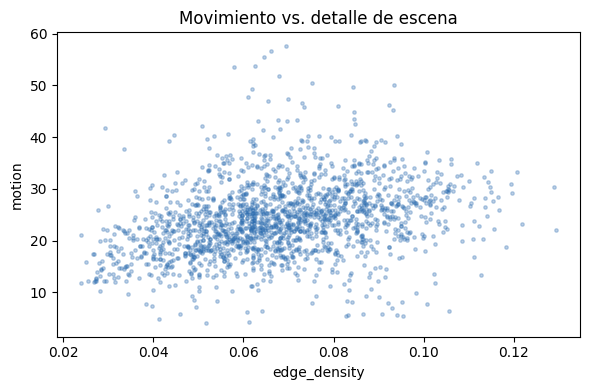

In [3]:
cols = ['motion','edge_density','green_ratio','player_count','contrast']
print(mv[cols].corr().round(2)['motion'])
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(mv.edge_density, mv.motion, s=6, alpha=0.3, color='#2b6cb0')
ax.set(xlabel='edge_density', ylabel='motion', title='Movimiento vs. detalle de escena')
fig.tight_layout(); fig.savefig('../outputs/16_motion_scatter.png'); plt.show()

El movimiento correlaciona con el contraste (+0.39) y el detalle de la escena (+0.30), y
negativamente con la cobertura de cancha (−0.31): los valores altos aparecen en cambios
de plano y tomas cerradas, no solo en jugadas. Con frames separados ≈3 s, `motion` mide
cambios de escena más que la trayectoria del balón; para detectar pases habrá que
calcularlo entre frames **sucesivos** (40 ms) o con flujo óptico.

## 3. Contexto: densidad temporal de pases (`train.csv`)

Pases totales: 3468
Segundos entre pases: media 9.9 | mediana 4.1


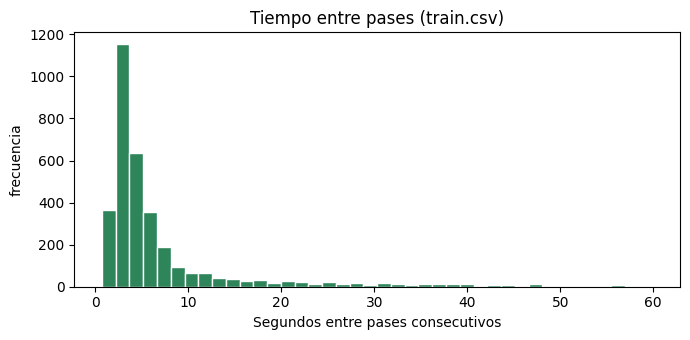

In [4]:
def toks(v):
    try: return ast.literal_eval(v) if isinstance(v,str) and v.strip() else []
    except: return []
plays = train[train.event=='play'].copy()
plays['is_pass'] = plays.event_attributes.apply(lambda x: 'pass' in toks(x))
passes = plays[plays.is_pass]
gap = passes.sort_values(['video_id','time']).groupby('video_id').time.diff().dropna()
print('Pases totales:', len(passes))
print('Segundos entre pases: media', round(gap.mean(),1), '| mediana', round(gap.median(),1))
fig, ax = plt.subplots(figsize=(7,3.5))
ax.hist(gap[gap<60], bins=40, color='#2f855a', edgecolor='white')
ax.set(xlabel='Segundos entre pases consecutivos', ylabel='frecuencia', title='Tiempo entre pases (train.csv)')
fig.tight_layout(); fig.savefig('../outputs/17_pass_gap.png'); plt.show()

Los pases ocurren **cada 4.1 s** (mediana; media 9.9 s por las pausas del juego): un
detector debe operar con buena resolución temporal, que los 25 fps de los clips permiten.

---
# 4. Hallazgos y conclusiones

**Hallazgos del análisis exploratorio**

1. **Datos homogéneos y de calidad.** 200 clips, 1080p a 25 fps, 30 s cada uno; sin
   corrupción, duplicados ni faltantes. Formato uniforme entre los 20 partidos.
2. **La cancha es fácil de aislar, pero depende del partido.** `green_ratio` (mediana
   0.61) separa las tomas de juego abierto de repeticiones y primeros planos (r = −0.47
   con `edge_density`), aunque su mediana varía de 0.42 a 0.81 entre partidos y
   depende del brillo (r = +0.61).
3. **Los jugadores son detectables.** YOLOv8 preentrenado detecta 11.9 jugadores por
   frame; el proxy por blobs (≈63 por frame) no correlaciona con YOLO y se descarta.
4. **Los equipos son separables por color de forma moderada.** Dentro de cada partido,
   k-means logra un *silhouette* medio de 0.41; hay que limpiar el recorte del torso.
5. **El movimiento marca cambios de escena.** Con frames cada ≈3 s refleja cortes de
   cámara; para pases se necesita resolución de frames sucesivos.
6. **Contexto de pases (train.csv):** 3,468 pases (96.7 % de las jugadas) frente a 118
   centros; el 93.1 % de las jugadas son pases de juego abierto (**desbalance fuerte**),
   con una mediana de 4.1 s entre pases.

**Retos identificados**

- El **balón** es pequeño y rápido: será lo más difícil de detectar.
- **Marca de agua y caja del marcador** superpuestas en todos los clips.
- **Variación de iluminación y encuadre** entre partidos.
- **Desbalance** de tipos de pase y **ausencia de etiquetas** en los clips descargables.

**Conclusiones y siguientes pasos**

- El dataset es **viable** para un sistema de detección de pases basado en visión.
- Pipeline propuesto: filtrar tomas cerradas con `green_ratio` → detectar jugadores y
  balón (YOLO, reentrenado con la clase balón) → asignar equipo por color dentro de cada
  partido → seguir el balón (tracking) → clasificar la acción con un modelo temporal,
  usando los picos de movimiento entre frames sucesivos como candidatos.
- Para **entrenar y evaluar** se necesitan los videos anotados (los `video_id` de
  `train.csv`) o etiquetar manualmente una muestra de los clips; el desbalance obliga a
  usar métricas por clase (F1, mAP temporal) y sobre-muestreo de balón parado.